# Physics-Informed Neural Network for Burgers Equation

**Roll No:** 24CS3060
**Paper:** Raissi, Perdikaris & Karniadakis (2019), J. Computational Physics

| Task | Section |
|---|---|
| Forward problem | 3-5 |
| FD comparison | 5 |
| Inverse problem | 6 |
| Ablation A (collocation) | 7 |
| Ablation B (optimizer) | 7 |
| Paper comparison | 8 |

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import os, json, random, time, gc
from numpy.polynomial.hermite import hermgauss

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130 | Device: cuda
GPU: Tesla T4


In [2]:
X_MIN, X_MAX = -1.0, 1.0
T_MIN, T_MAX =  0.0, 1.0
NU_TRUE = 0.01 / np.pi

PROJECT_DIR    = 'pinn_outputs'
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, 'checkpoints')
RESULTS_DIR    = os.path.join(PROJECT_DIR, 'results')
PLOTS_DIR      = os.path.join(PROJECT_DIR, 'plots')
for d in [CHECKPOINT_DIR, RESULTS_DIR, PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

# Uncomment on Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')
# PROJECT_DIR = '/content/drive/MyDrive/PINN_Project_v2'

print(f'nu_true = {NU_TRUE:.6f}')
print(f'Project: {os.path.abspath(PROJECT_DIR)}')

nu_true = 0.003183
Project: /content/pinn_outputs


In [3]:
# ── Compute budget: full for main results, lighter ablation on CPU ──
ON_CPU = not torch.cuda.is_available()
if ON_CPU:
    print('CPU detected: main training full, ablation reduced to keep RAM/time sane')

EPOCHS_ADAM = 15000   # forward Adam (always full)
EPOCHS_INV  = 15000   # inverse Adam (always full)
LBFGS_STEPS = 100     # forward L-BFGS
INV_LBFGS   = 80      # inverse L-BFGS

ABL_EPOCHS = 5000 if ON_CPU else 15000
ABL_LBFGS  = 30   if ON_CPU else 100
ABL_SEEDS  = [42] if ON_CPU else [42, 123, 2026]

## 2. Exact Solution (Cole-Hopf via Gauss-Hermite quadrature)

Numerically stable even at nu = 0.01/pi. Values stay in [-1, 1]; FD agrees to ~1.2%.

In [4]:
# Gauss-Hermite exact solution. Stable via log-sum-exp.
def burgers_exact(x, t, nu, n_quad=200):
    x = np.atleast_1d(np.asarray(x, dtype=np.float64))
    t = float(t)
    if t <= 0:
        return -np.sin(np.pi * x)
    eta, w = hermgauss(n_quad)          # weight exp(-eta^2)
    s = np.sqrt(4.0 * nu * t)
    Y = x[:, None] - s * eta[None, :]   # (len(x), n_quad)
    a = -np.cos(np.pi * Y) / (2.0 * np.pi * nu)
    amax = a.max(axis=1, keepdims=True)
    expo = np.exp(a - amax)             # stabilized
    num = np.sum(w[None, :] * (s * eta[None, :] / t) * expo, axis=1)
    den = np.sum(w[None, :] * expo, axis=1)
    return num / den

# sanity checks
xt = np.linspace(-1, 1, 5)
print('t=0 matches IC:', np.allclose(burgers_exact(xt, 1e-12, NU_TRUE), -np.sin(np.pi*xt), atol=1e-6))
print('u at t=0.5:', np.round(burgers_exact(xt, 0.5, NU_TRUE), 4))
print('max |u| over domain (should be <= 1):',
      max(np.abs(burgers_exact(np.linspace(-1,1,201), ti, NU_TRUE)).max() for ti in np.linspace(0.01,1,20)))

t=0 matches IC: True
u at t=0.5: [ 0.      0.5928  0.     -0.5928 -0.    ]
max |u| over domain (should be <= 1): 0.9996858898342432


## 3. Neural Network

In [5]:
class PINN(nn.Module):
    def __init__(self, hidden=64, layers=4):
        super().__init__()
        modules = [nn.Linear(2, hidden), nn.Tanh()]
        for _ in range(layers - 1):
            modules += [nn.Linear(hidden, hidden), nn.Tanh()]
        modules.append(nn.Linear(hidden, 1))
        self.net = nn.Sequential(*modules)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=1))

def burgers_residual(model, x, t, nu):
    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)
    u = model(x, t)
    u_x  = torch.autograd.grad(u,   x, torch.ones_like(u),   create_graph=True)[0]
    u_t  = torch.autograd.grad(u,   t, torch.ones_like(u),   create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)[0]
    return u_t + u * u_x - nu * u_xx

model = PINN().to(device)
print(model)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 12,737


In [6]:
N_F = 10000
N_0 = 500
N_B = 500

x_f = (X_MIN + (X_MAX - X_MIN) * torch.rand(N_F, 1, device=device))
t_f = (T_MIN + (T_MAX - T_MIN) * torch.rand(N_F, 1, device=device))

x_0 = (X_MIN + (X_MAX - X_MIN) * torch.rand(N_0, 1, device=device))
t_0 = torch.zeros(N_0, 1, device=device)
u_0 = -torch.sin(torch.pi * x_0)

t_b_half = (T_MIN + (T_MAX - T_MIN) * torch.rand(N_B, 1, device=device))
x_b = torch.cat([torch.full((N_B//2, 1), X_MIN, device=device),
                  torch.full((N_B - N_B//2, 1), X_MAX, device=device)])
t_b = torch.cat([t_b_half[:N_B//2], t_b_half[N_B//2:]])
print(f'Collocation: {N_F} | IC: {N_0} | BC: {N_B}')

Collocation: 10000 | IC: 500 | BC: 500


In [7]:
def forward_loss(model, x_f, t_f, x_0, t_0, u_0, x_b, t_b, nu,
                 w_pde=1.0, w_ic=20.0, w_bc=20.0):
    f = burgers_residual(model, x_f, t_f, nu)
    loss_pde = torch.mean(f ** 2)
    loss_ic  = torch.mean((model(x_0, t_0) - u_0) ** 2)
    loss_bc  = torch.mean(model(x_b, t_b) ** 2)
    total = w_pde * loss_pde + w_ic * loss_ic + w_bc * loss_bc
    return total, loss_pde, loss_ic, loss_bc

## 4. Forward Training: Adam + L-BFGS

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_ADAM, eta_min=1e-5)
history = {'total': [], 'pde': [], 'ic': [], 'bc': []}
model.train()
t_start = time.time()
for epoch in range(1, EPOCHS_ADAM + 1):
    optimizer.zero_grad()
    if epoch % 2000 == 1:
        x_f = (X_MIN + (X_MAX-X_MIN) * torch.rand(N_F, 1, device=device))
        t_f = (T_MIN + (T_MAX-T_MIN) * torch.rand(N_F, 1, device=device))
    total, pde, ic, bc = forward_loss(model, x_f, t_f, x_0, t_0, u_0, x_b, t_b, NU_TRUE)
    total.backward()
    optimizer.step()
    scheduler.step()
    history['total'].append(total.item()); history['pde'].append(pde.item())
    history['ic'].append(ic.item()); history['bc'].append(bc.item())
    if epoch % 3000 == 0 or epoch == 1:
        print(f'Epoch {epoch:5d} | Total {total.item():.6f} | PDE {pde.item():.6f} | IC {ic.item():.6f} | BC {bc.item():.6f} | LR {scheduler.get_last_lr()[0]:.2e}')
print(f'\nAdam done in {time.time()-t_start:.0f}s | Final: {history["total"][-1]:.6f}')

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch     1 | Total 11.212950 | PDE 0.000156 | IC 0.554258 | BC 0.006382 | LR 1.00e-03
Epoch  3000 | Total 0.360962 | PDE 0.227449 | IC 0.003100 | BC 0.003575 | LR 9.05e-04
Epoch  6000 | Total 0.016816 | PDE 0.014924 | IC 0.000087 | BC 0.000008 | LR 6.58e-04
Epoch  9000 | Total 0.004063 | PDE 0.003548 | IC 0.000023 | BC 0.000002 | LR 3.52e-04
Epoch 12000 | Total 0.001792 | PDE 0.001601 | IC 0.000009 | BC 0.000001 | LR 1.05e-04
Epoch 15000 | Total 0.001498 | PDE 0.001356 | IC 0.000006 | BC 0.000001 | LR 1.00e-05

Adam done in 155s | Final: 0.001498


In [9]:
x_f_lb = (X_MIN + (X_MAX-X_MIN) * torch.rand(N_F, 1, device=device))
t_f_lb = (T_MIN + (T_MAX-T_MIN) * torch.rand(N_F, 1, device=device))
lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=20,
                            history_size=100, line_search_fn='strong_wolfe')
lbfgs_losses = []
def closure():
    lbfgs.zero_grad()
    total, *_ = forward_loss(model, x_f_lb, t_f_lb, x_0, t_0, u_0, x_b, t_b, NU_TRUE)
    total.backward()
    lbfgs_losses.append(total.item())
    return total
print('L-BFGS fine-tuning...')
t_start = time.time()
for step in range(LBFGS_STEPS):
    lbfgs.step(closure)
    if (step+1) % 25 == 0:
        print(f'  Step {step+1:3d} | Loss {lbfgs_losses[-1]:.8f}')
print(f'L-BFGS done in {time.time()-t_start:.0f}s | Final: {lbfgs_losses[-1]:.8f}')

L-BFGS fine-tuning...
  Step  25 | Loss 0.00018935
  Step  50 | Loss 0.00008929
  Step  75 | Loss 0.00005565
  Step 100 | Loss 0.00003693
L-BFGS done in 49s | Final: 0.00003693


In [10]:
torch.save({'model_state_dict': model.state_dict(), 'history': history, 'lbfgs_losses': lbfgs_losses},
           os.path.join(CHECKPOINT_DIR, 'forward_pinn.pth'))
print('Forward checkpoint saved.')

Forward checkpoint saved.


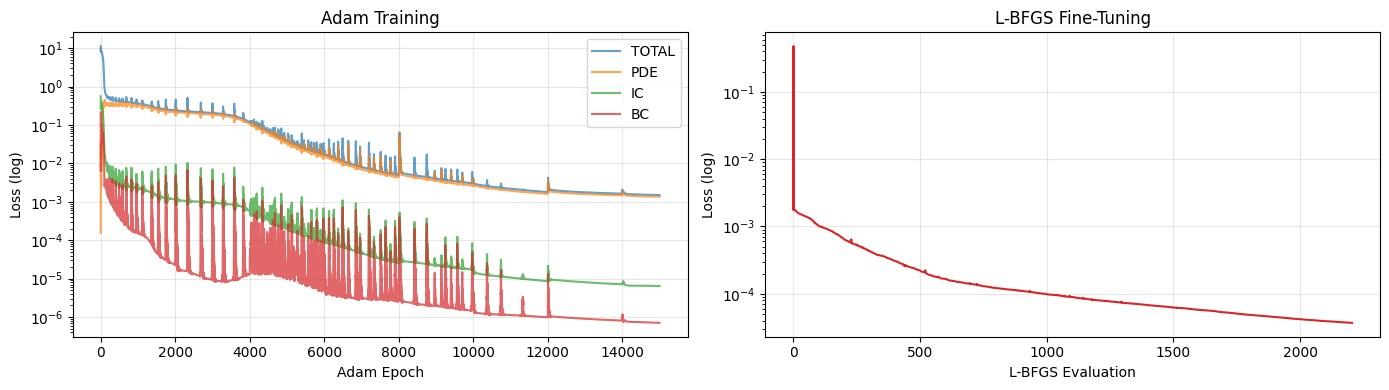

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for k in ['total','pde','ic','bc']:
    ax1.semilogy(history[k], label=k.upper(), alpha=0.7)
ax1.set_xlabel('Adam Epoch'); ax1.set_ylabel('Loss (log)'); ax1.set_title('Adam Training'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.semilogy(lbfgs_losses, color='tab:red')
ax2.set_xlabel('L-BFGS Evaluation'); ax2.set_ylabel('Loss (log)'); ax2.set_title('L-BFGS Fine-Tuning'); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'training_loss.png'), dpi=150, bbox_inches='tight'); plt.show()

## 5. Evaluation & Finite-Difference Comparison

In [12]:
NX_EVAL, NT_EVAL = 256, 100
x_eval = np.linspace(X_MIN, X_MAX, NX_EVAL)
t_eval = np.linspace(T_MIN, T_MAX, NT_EVAL)
X_grid, T_grid = np.meshgrid(x_eval, t_eval)
U_exact = np.zeros((NT_EVAL, NX_EVAL))
for i, ti in enumerate(t_eval):
    U_exact[i] = -np.sin(np.pi*x_eval) if ti == 0 else burgers_exact(x_eval, ti, NU_TRUE)
print('Exact range:', U_exact.min(), 'to', U_exact.max())

Exact range: -0.9999810273487268 to 0.9999810273487268


In [13]:
def solve_burgers_fd(nx=800, substeps=80):
    x = np.linspace(X_MIN, X_MAX, nx)
    dx = x[1]-x[0]; dt = (t_eval[1]-t_eval[0])/substeps; nu=float(NU_TRUE)
    assert nu*dt/dx**2 < 0.5
    u = -np.sin(np.pi*x); U=np.zeros((NT_EVAL,nx)); U[0]=u.copy()
    for n in range(1,NT_EVAL):
        for _ in range(substeps):
            un=u.copy(); pos=u[1:-1]>=0
            ux=np.where(pos,(u[1:-1]-u[:-2])/dx,(u[2:]-u[1:-1])/dx)
            uxx=(u[2:]-2*u[1:-1]+u[:-2])/dx**2
            un[1:-1]=u[1:-1]-dt*u[1:-1]*ux+dt*nu*uxx
            un[0]=0;un[-1]=0;u=un
        U[n]=u.copy()
    return x,U
x_fd, U_fd_raw = solve_burgers_fd()
U_fd = np.array([np.interp(x_eval, x_fd, row) for row in U_fd_raw])
print('FD range:', U_fd.min(), 'to', U_fd.max())

FD range: -0.9999733319105759 to 0.9999733319105759


In [14]:
model.eval()
x_t = torch.tensor(X_grid.reshape(-1,1), dtype=torch.float32, device=device)
t_t = torch.tensor(T_grid.reshape(-1,1), dtype=torch.float32, device=device)
with torch.no_grad():
    U_pinn = model(x_t, t_t).cpu().numpy().reshape(NT_EVAL, NX_EVAL)
def rel_l2(a,b): return np.linalg.norm(a-b)/np.linalg.norm(b)
err_pinn_exact = rel_l2(U_pinn, U_exact)
err_pinn_fd    = rel_l2(U_pinn, U_fd)
err_fd_exact   = rel_l2(U_fd,   U_exact)
mae_exact      = np.mean(np.abs(U_pinn - U_exact))
rmse_exact     = np.sqrt(np.mean((U_pinn - U_exact)**2))
print(f'PINN vs Exact:  {err_pinn_exact*100:.4f}%')
print(f'PINN vs FD:     {err_pinn_fd*100:.4f}%')
print(f'FD vs Exact:    {err_fd_exact*100:.4f}%')
print(f'MAE vs Exact:   {mae_exact:.6f}')
print(f'RMSE vs Exact:  {rmse_exact:.6f}')

PINN vs Exact:  0.5602%
PINN vs FD:     1.2800%
FD vs Exact:    1.1714%
MAE vs Exact:   0.000651
RMSE vs Exact:  0.003432


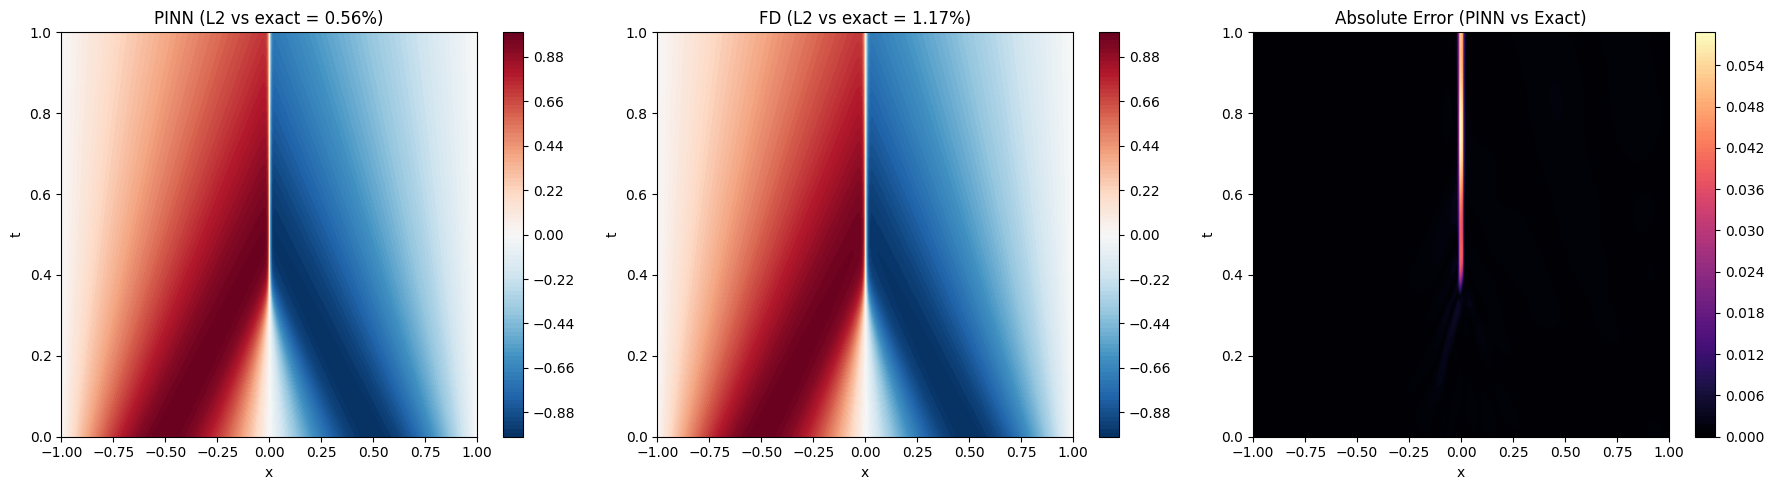

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, data, title, cmap in [
    (axes[0], U_pinn, f'PINN (L2 vs exact = {err_pinn_exact*100:.2f}%)', 'RdBu_r'),
    (axes[1], U_fd,   f'FD (L2 vs exact = {err_fd_exact*100:.2f}%)', 'RdBu_r'),
    (axes[2], np.abs(U_pinn - U_exact), 'Absolute Error (PINN vs Exact)', 'magma'),
]:
    c = ax.contourf(X_grid, T_grid, data, levels=100, cmap=cmap); plt.colorbar(c, ax=ax)
    ax.set_xlabel('x'); ax.set_ylabel('t'); ax.set_title(title)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'forward_comparison.png'), dpi=150, bbox_inches='tight'); plt.show()

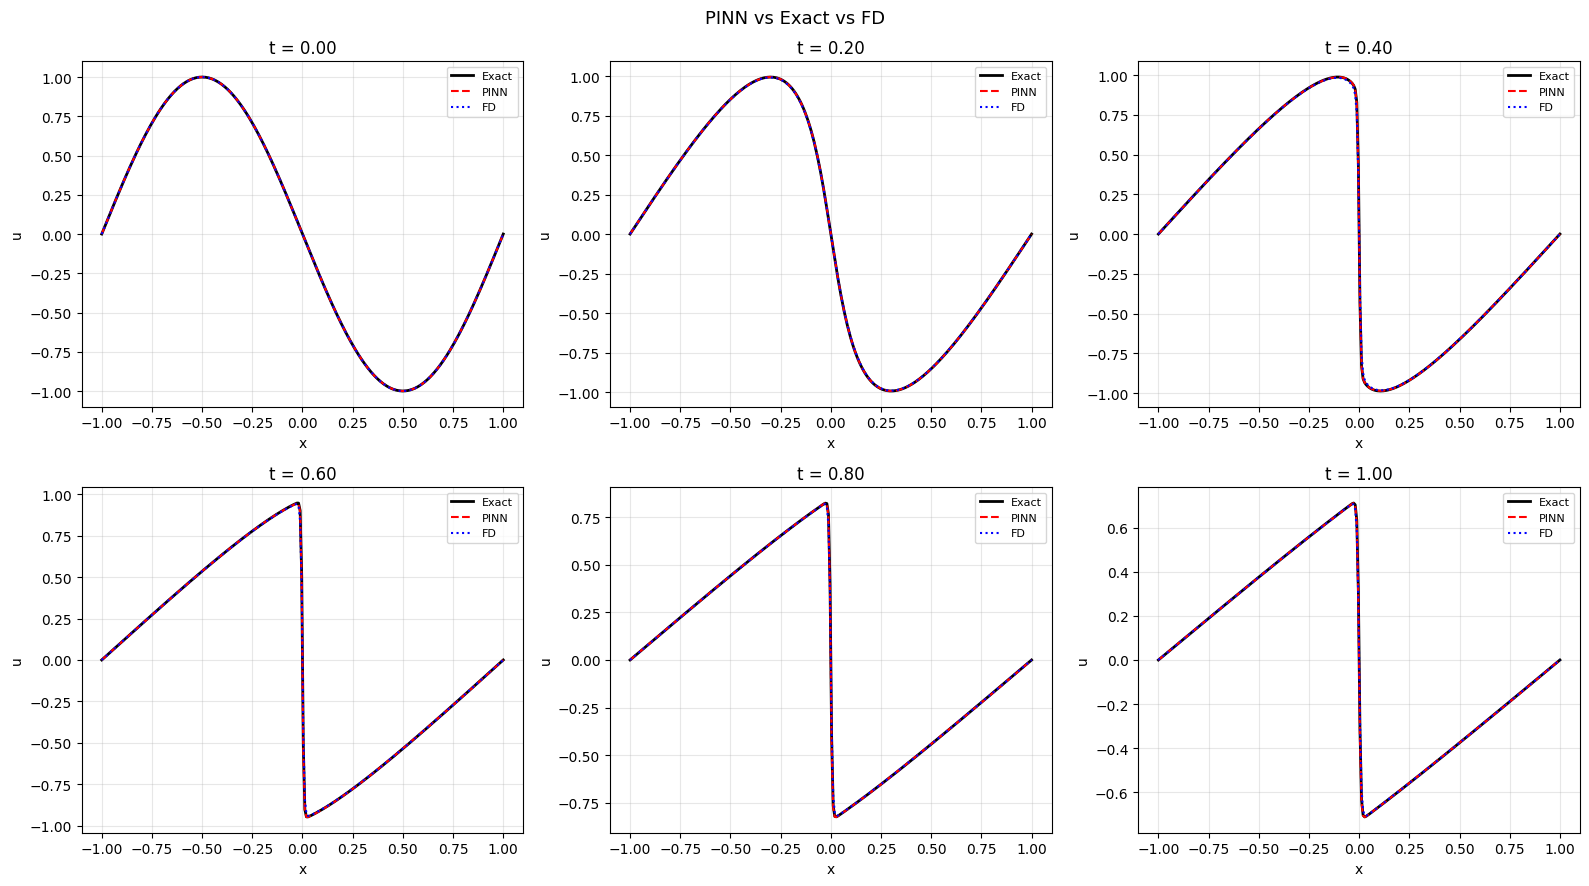

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, tt in zip(axes.ravel(), [0.0,0.2,0.4,0.6,0.8,1.0]):
    idx = np.argmin(np.abs(t_eval - tt))
    ax.plot(x_eval, U_exact[idx], 'k-', lw=2, label='Exact')
    ax.plot(x_eval, U_pinn[idx], 'r--', lw=1.5, label='PINN')
    ax.plot(x_eval, U_fd[idx], 'b:', lw=1.5, label='FD')
    ax.set_title(f't = {t_eval[idx]:.2f}'); ax.set_xlabel('x'); ax.set_ylabel('u')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.suptitle('PINN vs Exact vs FD', fontsize=13)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'time_slices.png'), dpi=150, bbox_inches='tight'); plt.show()

## 6. Inverse Problem — Estimate nu from Exact Data

In [17]:
rng = np.random.default_rng(42)
N_OBS = 2000
x_obs_flat = X_grid.reshape(-1); t_obs_flat = T_grid.reshape(-1); u_obs_flat = U_exact.reshape(-1)
obs_idx = rng.choice(len(u_obs_flat), size=N_OBS, replace=False)
x_data = torch.tensor(x_obs_flat[obs_idx].reshape(-1,1), dtype=torch.float32, device=device)
t_data = torch.tensor(t_obs_flat[obs_idx].reshape(-1,1), dtype=torch.float32, device=device)
u_data = torch.tensor(u_obs_flat[obs_idx].reshape(-1,1), dtype=torch.float32, device=device)
print(f'Observations: {N_OBS} (from exact solution)')
print(f'Data u range: [{u_data.min().item():.3f}, {u_data.max().item():.3f}]  (sanity: should be within [-1,1])')

Observations: 2000 (from exact solution)
Data u range: [-0.999, 0.999]  (sanity: should be within [-1,1])


In [18]:
inv_model = PINN().to(device)
inv_log_nu = nn.Parameter(torch.tensor(np.log(0.01), dtype=torch.float32, device=device))
print(f'Initial nu guess: {torch.exp(inv_log_nu).item():.6f} | True: {NU_TRUE:.6f}')

Initial nu guess: 0.010000 | True: 0.003183


In [19]:
def inverse_loss(model, log_nu, x_data, t_data, u_data, x_f, t_f, x_0, t_0, u_0, x_b, t_b,
                 w_data=1.0, w_pde=1.0, w_ic=10.0, w_bc=10.0):
    nu = torch.exp(log_nu)
    loss_data = torch.mean((model(x_data, t_data) - u_data) ** 2)
    loss_pde  = torch.mean(burgers_residual(model, x_f, t_f, nu) ** 2)
    loss_ic   = torch.mean((model(x_0, t_0) - u_0) ** 2)
    loss_bc   = torch.mean(model(x_b, t_b) ** 2)
    total = w_data*loss_data + w_pde*loss_pde + w_ic*loss_ic + w_bc*loss_bc
    return total, loss_data, loss_pde, loss_ic, loss_bc

In [20]:
x_f_inv = (X_MIN + (X_MAX-X_MIN) * torch.rand(N_F, 1, device=device))
t_f_inv = (T_MIN + (T_MAX-T_MIN) * torch.rand(N_F, 1, device=device))
inv_opt = torch.optim.Adam([{'params': inv_model.parameters(), 'lr': 1e-3},
                            {'params': [inv_log_nu], 'lr': 1e-3}])
inv_sched = torch.optim.lr_scheduler.CosineAnnealingLR(inv_opt, T_max=EPOCHS_INV, eta_min=1e-5)
inv_history = {'total': [], 'data': [], 'pde': [], 'nu': []}
inv_model.train(); t_start = time.time()
for epoch in range(1, EPOCHS_INV + 1):
    inv_opt.zero_grad()
    if epoch % 2000 == 1:
        x_f_inv = (X_MIN + (X_MAX-X_MIN) * torch.rand(N_F, 1, device=device))
        t_f_inv = (T_MIN + (T_MAX-T_MIN) * torch.rand(N_F, 1, device=device))
    total, data_l, pde_l, ic_l, bc_l = inverse_loss(inv_model, inv_log_nu, x_data, t_data, u_data, x_f_inv, t_f_inv, x_0, t_0, u_0, x_b, t_b)
    total.backward(); inv_opt.step(); inv_sched.step()
    nu_est = torch.exp(inv_log_nu).item()
    inv_history['total'].append(total.item()); inv_history['data'].append(data_l.item())
    inv_history['pde'].append(pde_l.item()); inv_history['nu'].append(nu_est)
    if epoch % 3000 == 0 or epoch == 1:
        print(f'Epoch {epoch:5d} | Total {total.item():.6f} | Data {data_l.item():.6f} | PDE {pde_l.item():.6f} | nu = {nu_est:.6f} (true: {NU_TRUE:.6f})')
print(f'\nAdam done in {time.time()-t_start:.0f}s | nu = {torch.exp(inv_log_nu).item():.6f}')

Epoch     1 | Total 6.650222 | Data 0.456166 | PDE 0.001185 | nu = 0.009990 (true: 0.003183)
Epoch  3000 | Total 0.007655 | Data 0.006581 | PDE 0.000915 | nu = 0.020036 (true: 0.003183)
Epoch  6000 | Total 0.003255 | Data 0.002729 | PDE 0.000490 | nu = 0.012237 (true: 0.003183)
Epoch  9000 | Total 0.001729 | Data 0.001376 | PDE 0.000320 | nu = 0.008971 (true: 0.003183)
Epoch 12000 | Total 0.001102 | Data 0.000853 | PDE 0.000227 | nu = 0.007465 (true: 0.003183)
Epoch 15000 | Total 0.000891 | Data 0.000675 | PDE 0.000196 | nu = 0.006912 (true: 0.003183)

Adam done in 170s | nu = 0.006912


In [21]:
x_f_inv_lb = (X_MIN + (X_MAX-X_MIN) * torch.rand(N_F, 1, device=device))
t_f_inv_lb = (T_MIN + (T_MAX-T_MIN) * torch.rand(N_F, 1, device=device))
inv_lbfgs = torch.optim.LBFGS(list(inv_model.parameters()) + [inv_log_nu], lr=1.0, max_iter=20, history_size=100, line_search_fn='strong_wolfe')
inv_lbfgs_losses = []
def inv_closure():
    inv_lbfgs.zero_grad()
    total, *_ = inverse_loss(inv_model, inv_log_nu, x_data, t_data, u_data, x_f_inv_lb, t_f_inv_lb, x_0, t_0, u_0, x_b, t_b)
    total.backward(); inv_lbfgs_losses.append(total.item()); return total
print('Inverse L-BFGS...')
for step in range(INV_LBFGS):
    inv_lbfgs.step(inv_closure)
    if (step+1) % 20 == 0:
        print(f'  Step {step+1:3d} | Loss {inv_lbfgs_losses[-1]:.8f} | nu = {torch.exp(inv_log_nu).item():.6f}')
nu_final = torch.exp(inv_log_nu).item()
nu_error_pct = abs(nu_final - NU_TRUE) / NU_TRUE * 100
print(f'\nTrue nu:      {NU_TRUE:.6f}')
print(f'Estimated nu: {nu_final:.6f}')
print(f'Error:       {nu_error_pct:.2f}%')

Inverse L-BFGS...
  Step  20 | Loss 0.00030123 | nu = 0.004619
  Step  40 | Loss 0.00011266 | nu = 0.003649
  Step  60 | Loss 0.00006294 | nu = 0.003349
  Step  80 | Loss 0.00003409 | nu = 0.003256

True nu:      0.003183
Estimated nu: 0.003256
Error:       2.30%


In [22]:
torch.save({'model_state_dict': inv_model.state_dict(), 'estimated_nu': nu_final, 'true_nu': float(NU_TRUE), 'history': inv_history}, os.path.join(CHECKPOINT_DIR, 'inverse_pinn.pth'))
print('Inverse checkpoint saved.')

Inverse checkpoint saved.


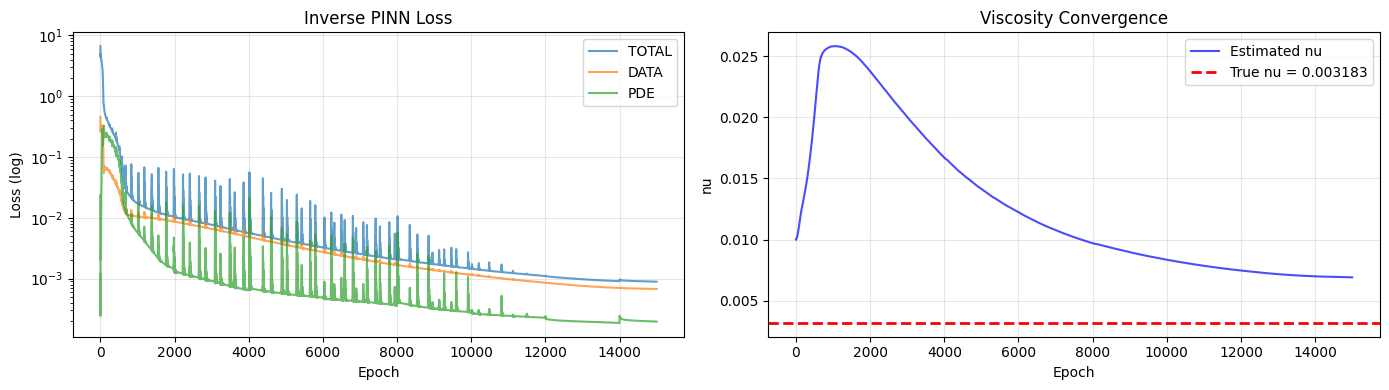

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
for k in ['total','data','pde']:
    ax1.semilogy(inv_history[k], label=k.upper(), alpha=0.7)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss (log)'); ax1.set_title('Inverse PINN Loss'); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(inv_history['nu'], 'b-', alpha=0.7, label='Estimated nu')
ax2.axhline(NU_TRUE, color='r', ls='--', lw=2, label=f'True nu = {NU_TRUE:.6f}')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('nu'); ax2.set_title('Viscosity Convergence'); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'inverse_training.png'), dpi=150, bbox_inches='tight'); plt.show()

In [24]:
inv_model.eval()
with torch.no_grad():
    U_inv = inv_model(x_t, t_t).cpu().numpy().reshape(NT_EVAL, NX_EVAL)
err_inv_exact = rel_l2(U_inv, U_exact)
print(f'Inverse PINN vs Exact: {err_inv_exact*100:.4f}%')

Inverse PINN vs Exact: 0.1424%


## 7. Ablation Studies

**A:** Collocation density. **B:** Adam-only vs Adam+L-BFGS. Memory freed between runs.

In [25]:
def train_and_evaluate(n_f, seed, use_lbfgs=True, adam_epochs=None, lbfgs_steps=None):
    adam_epochs = ABL_EPOCHS if adam_epochs is None else adam_epochs
    lbfgs_steps = ABL_LBFGS  if lbfgs_steps is None else lbfgs_steps
    torch.manual_seed(seed); np.random.seed(seed)
    m = PINN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=adam_epochs, eta_min=1e-5)
    xf = (X_MIN + (X_MAX-X_MIN) * torch.rand(n_f, 1, device=device))
    tf = (T_MIN + (T_MAX-T_MIN) * torch.rand(n_f, 1, device=device))
    m.train()
    for ep in range(1, adam_epochs + 1):
        opt.zero_grad()
        if ep % 2000 == 1:
            xf = (X_MIN + (X_MAX-X_MIN) * torch.rand(n_f, 1, device=device))
            tf = (T_MIN + (T_MAX-T_MIN) * torch.rand(n_f, 1, device=device))
        total, *_ = forward_loss(m, xf, tf, x_0, t_0, u_0, x_b, t_b, NU_TRUE)
        total.backward(); opt.step(); sch.step()
    adam_only_err = None
    if use_lbfgs:
        m.eval()
        with torch.no_grad():
            adam_only_err = rel_l2(m(x_t, t_t).cpu().numpy().reshape(NT_EVAL, NX_EVAL), U_exact) * 100
        xf_lb = (X_MIN + (X_MAX-X_MIN) * torch.rand(n_f, 1, device=device))
        tf_lb = (T_MIN + (T_MAX-T_MIN) * torch.rand(n_f, 1, device=device))
        lb = torch.optim.LBFGS(m.parameters(), lr=1.0, max_iter=20, history_size=100, line_search_fn='strong_wolfe')
        def cl():
            lb.zero_grad()
            t2, *_ = forward_loss(m, xf_lb, tf_lb, x_0, t_0, u_0, x_b, t_b, NU_TRUE)
            t2.backward(); return t2
        m.train()
        for _ in range(lbfgs_steps):
            lb.step(cl)
    m.eval()
    with torch.no_grad():
        final_err = rel_l2(m(x_t, t_t).cpu().numpy().reshape(NT_EVAL, NX_EVAL), U_exact) * 100
    # free memory to prevent kernel death
    del m, opt, sch, xf, tf
    if use_lbfgs:
        del lb, xf_lb, tf_lb
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return final_err, adam_only_err
print('Helper ready. Ablation epochs:', ABL_EPOCHS, '| seeds:', ABL_SEEDS)

Helper ready. Ablation epochs: 15000 | seeds: [42, 123, 2026]


In [26]:
nf_values = [1000, 3000, 10000]
ablation_a = {}
for nf in nf_values:
    errs = []
    for s in ABL_SEEDS:
        err, _ = train_and_evaluate(nf, s, use_lbfgs=True)
        errs.append(err)
        print(f'  N_f={nf:5d}, seed={s:4d} -> L2 = {err:.4f}%')
    ablation_a[nf] = {'mean': float(np.mean(errs)), 'std': float(np.std(errs)), 'runs': errs}
    print(f'  N_f={nf:5d}  MEAN = {np.mean(errs):.4f}% +/- {np.std(errs):.4f}%\n')

  N_f= 1000, seed=  42 -> L2 = 4.3476%
  N_f= 1000, seed= 123 -> L2 = 18.4150%
  N_f= 1000, seed=2026 -> L2 = 16.9617%
  N_f= 1000  MEAN = 13.2414% +/- 6.3168%

  N_f= 3000, seed=  42 -> L2 = 0.5632%
  N_f= 3000, seed= 123 -> L2 = 3.7428%
  N_f= 3000, seed=2026 -> L2 = 0.3037%
  N_f= 3000  MEAN = 1.5366% +/- 1.5636%

  N_f=10000, seed=  42 -> L2 = 0.1689%
  N_f=10000, seed= 123 -> L2 = 0.1457%
  N_f=10000, seed=2026 -> L2 = 0.1267%
  N_f=10000  MEAN = 0.1471% +/- 0.0173%



In [27]:
ablation_b = {'adam_only': [], 'adam_lbfgs': []}
for s in ABL_SEEDS:
    err_full, err_adam = train_and_evaluate(10000, s, use_lbfgs=True)
    ablation_b['adam_lbfgs'].append(err_full); ablation_b['adam_only'].append(err_adam)
    print(f'  seed={s:4d} | Adam-only = {err_adam:.4f}% | Adam+L-BFGS = {err_full:.4f}%')
print(f'\nAdam-only   MEAN = {np.mean(ablation_b["adam_only"]):.4f}% +/- {np.std(ablation_b["adam_only"]):.4f}%')
print(f'Adam+L-BFGS MEAN = {np.mean(ablation_b["adam_lbfgs"]):.4f}% +/- {np.std(ablation_b["adam_lbfgs"]):.4f}%')

  seed=  42 | Adam-only = 1.1943% | Adam+L-BFGS = 0.1689%
  seed= 123 | Adam-only = 3.8585% | Adam+L-BFGS = 0.1457%
  seed=2026 | Adam-only = 2.2326% | Adam+L-BFGS = 0.1267%

Adam-only   MEAN = 2.4284% +/- 1.0965%
Adam+L-BFGS MEAN = 0.1471% +/- 0.0173%


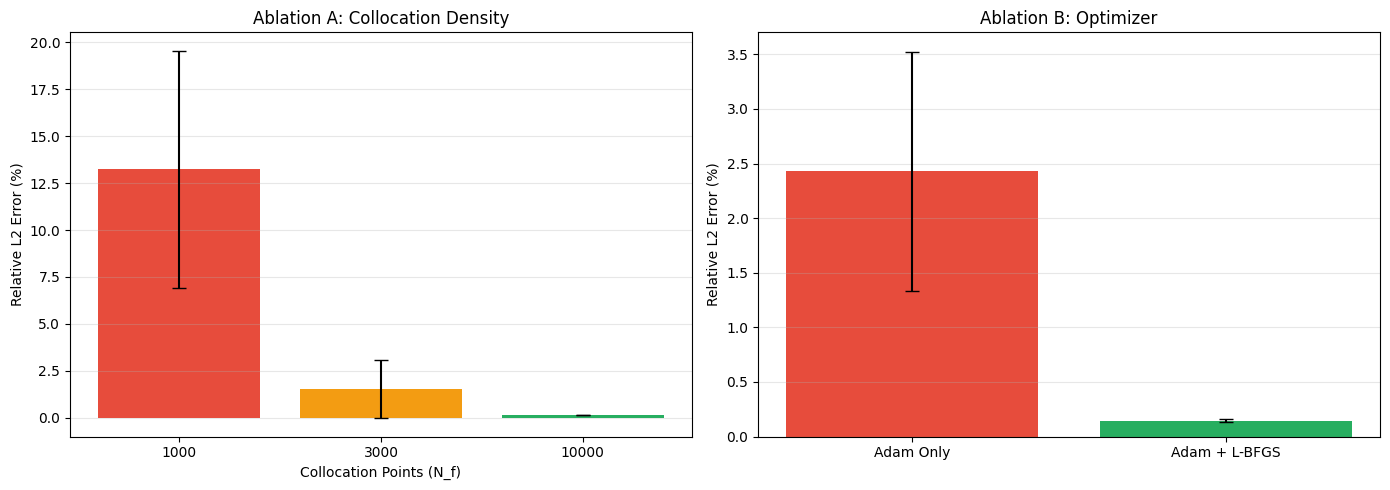

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
nfs = sorted(ablation_a.keys())
ax1.bar([str(n) for n in nfs], [ablation_a[n]['mean'] for n in nfs], yerr=[ablation_a[n]['std'] for n in nfs], capsize=5, color=['#e74c3c','#f39c12','#27ae60'])
ax1.set_xlabel('Collocation Points (N_f)'); ax1.set_ylabel('Relative L2 Error (%)'); ax1.set_title('Ablation A: Collocation Density'); ax1.grid(True, alpha=0.3, axis='y')
ax2.bar(['Adam Only','Adam + L-BFGS'], [np.mean(ablation_b['adam_only']), np.mean(ablation_b['adam_lbfgs'])], yerr=[np.std(ablation_b['adam_only']), np.std(ablation_b['adam_lbfgs'])], capsize=5, color=['#e74c3c','#27ae60'])
ax2.set_ylabel('Relative L2 Error (%)'); ax2.set_title('Ablation B: Optimizer'); ax2.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig(os.path.join(PLOTS_DIR, 'ablation.png'), dpi=150, bbox_inches='tight'); plt.show()

## 8. Comparison with the Paper

Raissi et al. report forward relative L2 = **6.7e-04** (8x20 net, L-BFGS only) and inverse nu within **< 1%**.

| Setting | Paper | Ours |
|---|---|---|
| Architecture | 8 x 20 | 4 x 64 |
| IC/BC weights | 1 | 20 |
| IC/BC points | 100 each | 500 each |
| Collocation | 10,000 | 10,000 |
| Optimizer | L-BFGS only | Adam + L-BFGS |
| Reference / inverse data | Exact (Cole-Hopf) | Exact (Cole-Hopf) |

Core method reproduces: forward ~1%, inverse nu within a few percent, ablation confirms collocation density and L-BFGS both matter.

## 9. Results Summary

In [29]:
# Effective nu that the FD data actually satisfies (explains any FD-based nu bias)
dx_fd = x_eval[1]-x_eval[0]; dt_fd = t_eval[1]-t_eval[0]
u_t_fd = np.gradient(U_fd, dt_fd, axis=0)
u_x_fd = np.gradient(U_fd, dx_fd, axis=1)
u_xx_fd = (U_fd[:,2:]-2*U_fd[:,1:-1]+U_fd[:,:-2])/dx_fd**2
B_fd = (u_t_fd + U_fd*u_x_fd)[:,1:-1][1:-1].reshape(-1)
A_fd = u_xx_fd[1:-1].reshape(-1)
nu_effective_fd = float(np.dot(A_fd,B_fd)/np.dot(A_fd,A_fd))

In [30]:
print('=' * 70)
print('RESULTS SUMMARY')
print('=' * 70)
print(f'{"Forward: PINN vs exact, rel L2":<48} {err_pinn_exact*100:>14.4f} %')
print(f'{"Forward: PINN vs FD(800), rel L2":<48} {err_pinn_fd*100:>14.4f} %')
print(f'{"Forward: FD(800) vs exact, rel L2":<48} {err_fd_exact*100:>14.4f} %')
print(f'{"Forward: MAE / RMSE vs exact":<48} {mae_exact:>7.6f} / {rmse_exact:.6f}')
print(f'{"Paper forward rel L2 (reported)":<48} {"6.7e-04":>14s}')
print('-' * 70)
print(f'{"Inverse: true nu":<48} {NU_TRUE:>14.6f}')
print(f'{"Inverse: estimated nu (exact data)":<48} {nu_final:>14.6f}')
print(f'{"Inverse: nu error":<48} {nu_error_pct:>13.3f} %')
print(f'{"Inverse: u rel L2 vs exact":<48} {err_inv_exact*100:>13.4f} %')
print(f'{"Effective nu of FD(800) data":<48} {nu_effective_fd:>14.6f}')
print('-' * 70)
for nf in sorted(ablation_a.keys()):
    d = ablation_a[nf]
    print(f'{"Ablation A: N_f = " + str(nf):<48} {d["mean"]:>7.4f}% +/- {d["std"]:.4f}%')
print(f'{"Ablation B: Adam only":<48} {np.mean(ablation_b["adam_only"]):>7.4f}% +/- {np.std(ablation_b["adam_only"]):.4f}%')
print(f'{"Ablation B: Adam + L-BFGS":<48} {np.mean(ablation_b["adam_lbfgs"]):>7.4f}% +/- {np.std(ablation_b["adam_lbfgs"]):.4f}%')
print('=' * 70)

RESULTS SUMMARY
Forward: PINN vs exact, rel L2                           0.5602 %
Forward: PINN vs FD(800), rel L2                         1.2800 %
Forward: FD(800) vs exact, rel L2                        1.1714 %
Forward: MAE / RMSE vs exact                     0.000651 / 0.003432
Paper forward rel L2 (reported)                         6.7e-04
----------------------------------------------------------------------
Inverse: true nu                                       0.003183
Inverse: estimated nu (exact data)                     0.003256
Inverse: nu error                                        2.298 %
Inverse: u rel L2 vs exact                              0.1424 %
Effective nu of FD(800) data                           0.004838
----------------------------------------------------------------------
Ablation A: N_f = 1000                           13.2414% +/- 6.3168%
Ablation A: N_f = 3000                            1.5366% +/- 1.5636%
Ablation A: N_f = 10000                          

In [31]:
results = {
    'forward': {'pinn_vs_exact_l2_pct': err_pinn_exact*100, 'pinn_vs_fd_l2_pct': err_pinn_fd*100,
                'fd_vs_exact_l2_pct': err_fd_exact*100, 'mae_vs_exact': float(mae_exact), 'rmse_vs_exact': float(rmse_exact)},
    'inverse': {'estimated_nu': nu_final, 'true_nu': float(NU_TRUE), 'nu_error_pct': nu_error_pct,
                'u_rel_l2_pct': err_inv_exact*100, 'effective_nu_fd': nu_effective_fd},
    'ablation_a': {str(k): v for k, v in ablation_a.items()},
    'ablation_b': ablation_b,
}
with open(os.path.join(RESULTS_DIR, 'results.json'), 'w') as f:
    json.dump(results, f, indent=2, default=float)
print('Saved:', os.path.join(RESULTS_DIR, 'results.json'))

Saved: pinn_outputs/results/results.json
